Features:
RETRIEVAL FROM TTNN
----
two_tower_score
two_tower_rank
two_tower_score_z
DONE

USER
----
user_rating_mean
user_rating_std
user_rating_count
DONE


MOVIE
-----
runtime (TMDB)
popularity (TMDB)
release_year - DONE
vote_count (TMDB)



USER × MOVIE
------------
genre_affinity - DONE
decade_affinity - DONE
content_cosine_similarity
language_affinity (waiting for user features)

In [2]:
import numpy as np
import pandas as pd
from xgboost import XGBRegressor
import xgboost as xgb
from sklearn.metrics import mean_squared_error, r2_score

In [3]:
# from recommender script 
train_candidate_preds_ranked  = pd.read_parquet("../data/train_candidate_preds_ranked.parquet")
test_candidate_preds_ranked  = pd.read_parquet("../data/test_candidate_preds_ranked.parquet")

# ['userId', 'movieId', 'rating', 'user_avg_rating', 'user_std_rating', 'user_count_rating', 'movie_Release_Year', 'genre_affinity', 'decade_affinity', 'predicted_rating', 'user_rank', 'z_score']

In [4]:
X_train = train_candidate_preds_ranked[[
    "user_avg_rating",
    "user_std_rating",
    "user_count_rating",
    "movie_Release_Year",
    "genre_affinity",
    "decade_affinity",
    "predicted_rating",
    "user_rank",
    "z_score"
]]
y_train = train_candidate_preds_ranked["rating"]

X_test = test_candidate_preds_ranked[[
    "user_avg_rating",
    "user_std_rating",
    "user_count_rating",
    "movie_Release_Year",
    "genre_affinity",
    "decade_affinity",
    "predicted_rating",
    "user_rank",
    "z_score"
]]
y_test = test_candidate_preds_ranked["rating"]


In [5]:
model = xgb.XGBRegressor(eval_metric="rmse", objective="reg:squarederror",
                         n_estimators=100, random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

In [6]:
# eval
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

print("baseline\n")

train_rmse = np.sqrt(mean_squared_error(y_train, model.predict(X_train)))
train_mae = mean_absolute_error(y_train, model.predict(X_train))
train_r2 = r2_score(y_train, model.predict(X_train))

test_rmse = np.sqrt(mean_squared_error(y_test, y_pred))
test_mae = mean_absolute_error(y_test, y_pred)
test_r2 = r2_score(y_test, y_pred)

print(f"Training RMSE: {train_rmse:.4f}")
print(f"Training MAE:  {train_mae:.4f}")
print(f"Training R²:   {train_r2:.4f}")

print()

print(f"Test RMSE:       {test_rmse:.4f}")
print(f"Test MAE:        {test_mae:.4f}")
print(f"Test R²:         {test_r2:.4f}")

baseline

Training RMSE: 0.7239
Training MAE:  0.5492
Training R²:   0.5087

Test RMSE:       0.9052
Test MAE:        0.6811
Test R²:         0.2346


In [10]:
#hyperparameter tuning
from sklearn.model_selection import GridSearchCV

param_grid = {
    'max_depth': [3, 4, 5, 6, 7, 8],
    'learning_rate': [0.01, 0.1, 0.2],
    'subsample': [0.6, 0.8, 1.0],
    'colsample_bytree': [0.8, 1.0]
}

grid_search = GridSearchCV(
    estimator=model, param_grid=param_grid, cv=5, scoring="neg_root_mean_squared_error", n_jobs=-1, verbose=1)
grid_search.fit(X_train, y_train)

print("Best parameters:", grid_search.best_params_)

Fitting 5 folds for each of 108 candidates, totalling 540 fits
Best parameters: {'colsample_bytree': 1.0, 'learning_rate': 0.1, 'max_depth': 6, 'subsample': 0.8}


In [8]:
# eval best model

best_model = grid_search.best_estimator_

# new predictions from tuned model
y_train_pred_tuned = best_model.predict(X_train)
y_test_pred_tuned = best_model.predict(X_test)

# Training metrics
train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred_tuned))
train_mae = mean_absolute_error(y_train, y_train_pred_tuned)
train_r2 = r2_score(y_train, y_train_pred_tuned)

# Test metrics
test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred_tuned))
test_mae = mean_absolute_error(y_test, y_test_pred_tuned)
test_r2 = r2_score(y_test, y_test_pred_tuned)

print("tuned\n")

print(f"Training RMSE: {train_rmse:.4f}")
print(f"Training MAE:  {train_mae:.4f}")
print(f"Training R²:   {train_r2:.4f}")

print()

print(f"Test RMSE:     {test_rmse:.4f}")
print(f"Test MAE:      {test_mae:.4f}")
print(f"Test R²:       {test_r2:.4f}")

tuned

Training RMSE: 0.7412
Training MAE:  0.5625
Training R²:   0.4849

Test RMSE:     0.8702
Test MAE:      0.6531
Test R²:       0.2926


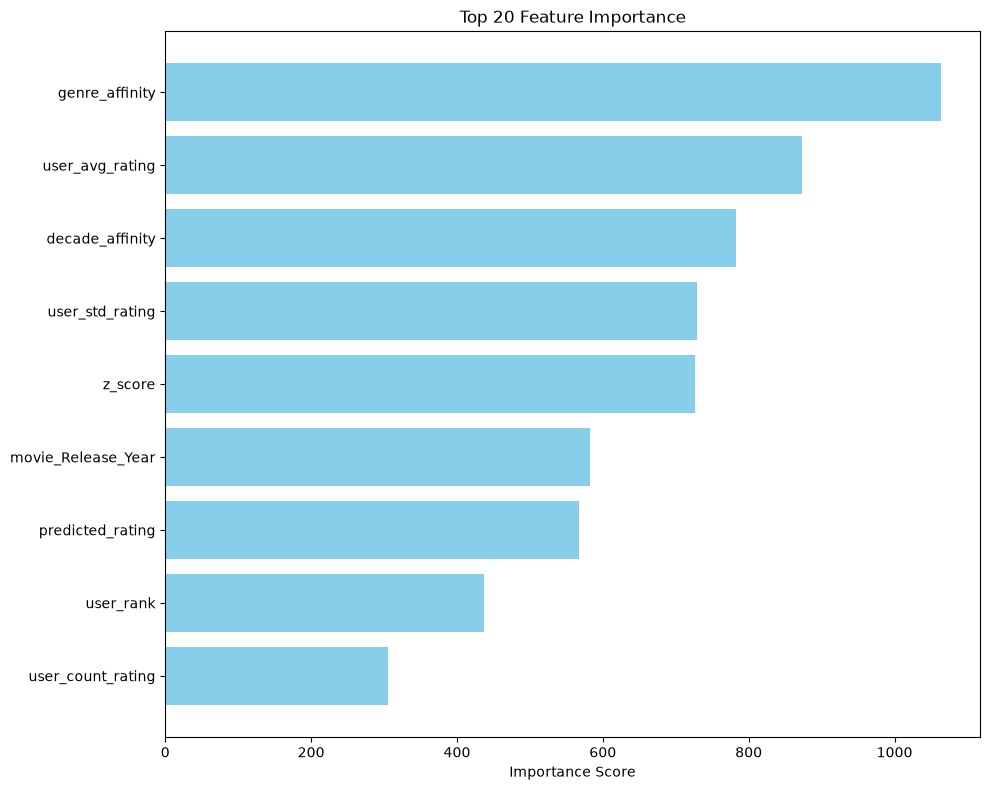

In [11]:
#feature importance vis
import matplotlib.pyplot as plt

importance = best_model.get_booster().get_score(importance_type='weight')

importance_df = pd.DataFrame({
    'Feature': list(importance.keys()),
    'Importance': list(importance.values())
}).sort_values(by='Importance', ascending=False)

top_n = 20
plt.figure(figsize=(10, 8))
plt.barh(
    importance_df['Feature'].head(top_n)[::-1],
    importance_df['Importance'].head(top_n)[::-1],
    color='skyblue'
)
plt.xlabel('Importance Score')
plt.title(f'Top {top_n} Feature Importance')
plt.tight_layout()
plt.show()

In [13]:
best_model.save_model("../models/xgboost_model.json")